# Veri Ön İşleme Uygulaması (Pandas & NumPy)

**Veri seti:** Titanic  


## 1. Kütüphanelerin yüklenmesi ve veri setinin alınması


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Titanic veri setini seaborn üzerinden yükle.
df = sns.load_dataset("titanic")

# İlk 5 satırı görüntüle
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Sütun veri tiplerinin incelenmesi

Sayısal ve kategorik değişkenleri veri tiplerine göre ayırılması


In [2]:
# Tüm sütunların veri tiplerini görüntüle
print("Sütun veri tipleri:")
print(df.dtypes)

# NumPy'nin number veri tipini kullanarak sayısal sütunları seç
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Sayısal olmayan sütunları kategorik değişkenler olarak ele al
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("\nSayısal değişkenler:")
print(numeric_cols)

print("\nKategorik değişkenler:")
print(categorical_cols)


Sütun veri tipleri:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

Sayısal değişkenler:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Kategorik değişkenler:
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


## 3. Eksik verilerin tespit edilmesi ve doldurulması

- Sayısal eksik değerler **median** ile,
- kategorik eksik değerler **mode** ile doldurulmaktadır.


In [4]:
# Her sütundaki eksik değer sayısını kontrol et
missing_before = df.isnull().sum()
print("Eksik değerler (doldurma öncesi):")
print(missing_before[missing_before > 0])


Eksik değerler (doldurma öncesi):
age            177
embarked         2
deck           688
embark_town      2
dtype: int64


In [5]:
# Orijinal veri setini korumak için bir kopya oluştur
df_processed = df.copy()

# Sayısal sütunlardaki eksik değerleri median ile doldur
for col in numeric_cols:
    if df_processed[col].isnull().any():
        df_processed[col] = df_processed[col].fillna(df_processed[col].median())

# Kategorik sütunlardaki eksik değerleri mode ile doldur
for col in categorical_cols:
    if df_processed[col].isnull().any():
        mode_value = df_processed[col].mode(dropna=True)[0]
        df_processed[col] = df_processed[col].fillna(mode_value)

print("Eksik değerler (doldurma sonrası):")
print(df_processed.isnull().sum()[df_processed.isnull().sum() > 0])

print("\nToplam eksik değer sayısı:", int(df_processed.isnull().sum().sum()))


Eksik değerler (doldurma sonrası):
Series([], dtype: int64)

Toplam eksik değer sayısı: 0


## 4. Z-score standardizasyonu

`age` değişkenine Z-score standardizasyonu uygulanmaktadır.

`z = (x - ortalama) / standart sapma`


In [6]:
# Yaş değişkeninin ortalamasını ve standart sapmasını hesapla
age_mean = np.mean(df_processed["age"])
age_std = np.std(df_processed["age"], ddof=0)

# Z-score standardizasyonunu uygula
df_processed["age_zscore"] = (df_processed["age"] - age_mean) / age_std

df_processed[["age", "age_zscore"]].head()


,age,age_zscore
0,22.0,-0.565736
1,38.0,0.663861
2,26.0,-0.258337
3,35.0,0.433312
4,35.0,0.433312


## 5. Min-Max normalizasyonu

`fare` değişkenini 0 ile 1 aralığına dönüştürüyoruz.

`x' = (x - min) / (max - min)`


In [7]:
fare_min = df_processed["fare"].min()
fare_max = df_processed["fare"].max()

# Min-Max normalizasyonu
df_processed["fare_minmax"] = (
    (df_processed["fare"] - fare_min) / (fare_max - fare_min)
)

df_processed[["fare", "fare_minmax"]].head()


,fare,fare_minmax
0,7.2500,0.014151
1,71.2833,0.139136
2,7.9250,0.015469
3,53.1000,0.103644
4,8.0500,0.015713


## 6. Kategorik değişkenlerin kodlanması

İki farklı örnek gösterilmektedir:

1. `sex` değişkenine **Label Encoding**
2. `embarked` değişkenine **One-Hot Encoding**


In [8]:
# Label Encoding: female -> 1, male -> 0
df_processed["sex_label"] = df_processed["sex"].map({
    "male": 0,
    "female": 1
})

df_processed[["sex", "sex_label"]].head()


,sex,sex_label
0,male,0
1,female,1
2,female,1
3,female,1
4,male,0


In [9]:
# One-Hot Encoding: embarked sütunundaki kategoriler ayrı sütunlara dönüştürülüyor.
embarked_dummies = pd.get_dummies(
    df_processed["embarked"],
    prefix="embarked",
    dtype=int
)

df_processed = pd.concat([df_processed, embarked_dummies], axis=1)

embarked_dummies.head()


,embarked_C,embarked_Q,embarked_S
0,0,0,1
1,1,0,0
2,0,0,1
3,0,0,1
4,0,0,1


## 7. Veri görselleştirme

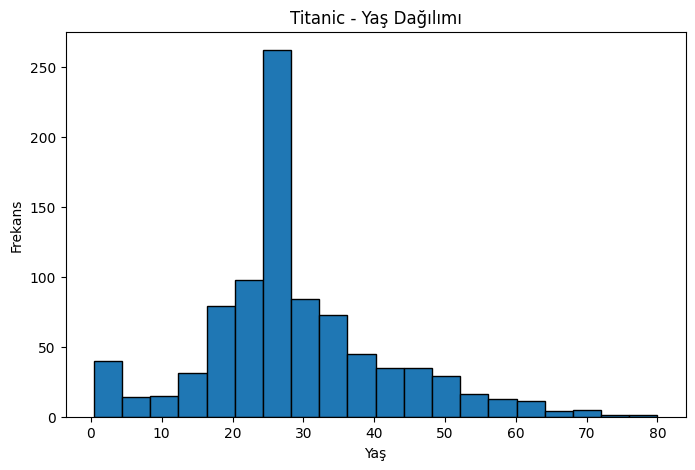

In [10]:
# Yaş dağılımını histogram ile incele
plt.figure(figsize=(8, 5))
plt.hist(df_processed["age"], bins=20, edgecolor="black")
plt.title("Titanic - Yaş Dağılımı")
plt.xlabel("Yaş")
plt.ylabel("Frekans")
plt.show()


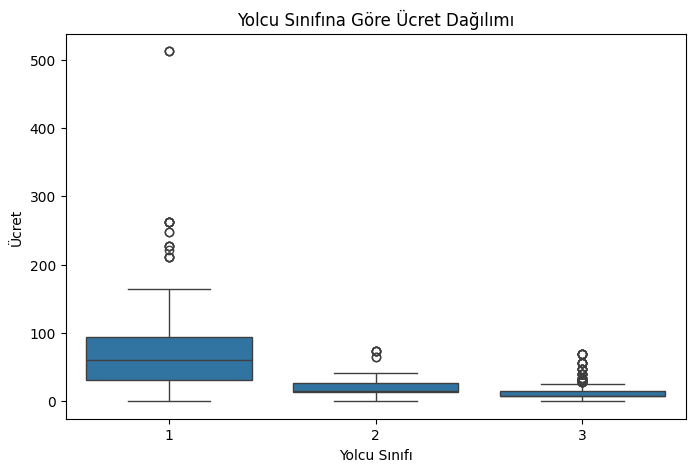

In [11]:
# Yolcu sınıfına göre ücret dağılımını boxplot ile incele
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_processed, x="pclass", y="fare")
plt.title("Yolcu Sınıfına Göre Ücret Dağılımı")
plt.xlabel("Yolcu Sınıfı")
plt.ylabel("Ücret")
plt.show()


## Son kontrol


In [12]:
result_cols = [
    "age",
    "age_zscore",
    "fare",
    "fare_minmax",
    "sex",
    "sex_label",
    "embarked"
]

# One-Hot Encoding ile oluşan sütunları da ekle
result_cols += [col for col in df_processed.columns if col.startswith("embarked_")]

df_processed[result_cols].head()


,age,age_zscore,fare,fare_minmax,sex,sex_label,embarked,embarked_C,embarked_Q,embarked_S
0,22.0,-0.565736,7.2500,0.014151,male,0,S,0,0,1
1,38.0,0.663861,71.2833,0.139136,female,1,C,1,0,0
2,26.0,-0.258337,7.9250,0.015469,female,1,S,0,0,1
3,35.0,0.433312,53.1000,0.103644,female,1,S,0,0,1
4,35.0,0.433312,8.0500,0.015713,male,0,S,0,0,1
